# 05 Multilingual Analysis

Extracted from `FP_NewsBot2_ksm_GroupName_ITAI2373.ipynb` (original outputs kept). Contains the setup cells it depends on (dataset load, preprocessing, validation, and any earlier modules it uses).

Upload `BBC News Train.csv` (in `data/raw/`) to Colab before running.

## 📦 Final Project Setup
We need two extra libraries for the multilingual part. The cell also makes sure the dataset is loaded
(the same `newsbot_dataset.csv` we made in the midterm from the Kaggle **BBC News Train.csv**), so the
final-project part can run even after a Colab restart.

In [1]:
!pip install -q langdetect deep-translator

import os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'vader_lexicon']:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer

# Load the dataset the same way as the midterm (Kaggle 'BBC News Train.csv' -> newsbot_dataset.csv)
if 'df' not in globals() or 'content' not in df.columns or len(df) < 1000:
    if os.path.exists('newsbot_dataset.csv'):
        df = pd.read_csv('newsbot_dataset.csv')
    else:
        df = pd.read_csv('BBC News Train.csv').rename(
            columns={'ArticleId': 'article_id', 'Text': 'content', 'Category': 'category'})
df = df[['article_id', 'content', 'category']].dropna().reset_index(drop=True)
print('Articles:', len(df))
print(df['category'].value_counts())

Articles: 1490
category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64


In [2]:
# Preprocessing functions (same steps as our midterm, plus a sentence splitter for summaries)
"""Text cleaning and preprocessing (enhanced from our midterm)."""
import re
import nltk

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "vader_lexicon"]:
    try:
        nltk.download(pkg, quiet=True)
    except Exception:
        pass

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

_lemmatizer = WordNetLemmatizer()
_stop_words = set(stopwords.words("english"))


def clean_text(text):
    """Lowercase, remove HTML, URLs, emails, numbers and symbols."""
    if text is None:
        return ""
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", "", text)
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    text = re.sub(r"\S+@\S+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    return re.sub(r"\s+", " ", text).strip()


def preprocess_text(text):
    """Clean + remove stop words + lemmatize + drop very short words."""
    tokens = clean_text(text).split()
    tokens = [_lemmatizer.lemmatize(t) for t in tokens if t not in _stop_words]
    return " ".join(t for t in tokens if len(t) > 2)


def split_sentences(text):
    """Split an article into sentences (BBC text uses '. ' between sentences)."""
    try:
        sents = nltk.sent_tokenize(str(text))
    except Exception:
        sents = re.split(r"(?<=[.!?])\s+", str(text))
    return [s.strip() for s in sents if len(s.split()) >= 4]

df['processed'] = df['content'].apply(preprocess_text)
print('Preprocessing done. Example:', df['processed'][0][:120])

Preprocessing done. Example: worldcom exboss launch defence lawyer defending former worldcom chief bernie ebbers battery fraud charge called company 


### 🧪 Data quality check (new)
While building the final project we found something we missed in the midterm: some articles in the BBC
training file are **exact duplicates**. If the same article is in both train and test, the accuracy looks
better than it really is. So we count them and remove them for the final project models.

In [3]:
"""Data quality checks before analysis."""
import logging
import pandas as pd

log = logging.getLogger(__name__)
REQUIRED = ["article_id", "content", "category"]


def _load_bbc_unused(path):
    """Load the Kaggle 'BBC News Train.csv' and rename columns like the midterm."""
    df = pd.read_csv(path)
    df = df.rename(columns={"ArticleId": "article_id", "Text": "content", "Category": "category"})
    return validate(df)


def validate(df):
    """Drop missing/empty/duplicate articles and print a short report."""
    missing = [c for c in REQUIRED if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")
    before = len(df)
    df = df.dropna(subset=["content", "category"])
    df = df[df["content"].str.strip().str.len() > 0]
    n_dup = int(df.duplicated(subset="content").sum())
    df = df.drop_duplicates(subset="content").reset_index(drop=True)
    report = {"rows_in": before, "rows_out": len(df), "duplicates_removed": n_dup,
              "categories": df["category"].value_counts().to_dict()}
    log.info("Data validation: %s", report)
    df.attrs["validation_report"] = report
    return df

df_full = df.copy()                 # midterm version (1490 articles)
df = validate(df)                   # final project version (duplicates removed)
print(df.attrs['validation_report'])

{'rows_in': 1490, 'rows_out': 1440, 'duplicates_removed': 50, 'categories': {'sport': 342, 'business': 335, 'politics': 266, 'entertainment': 263, 'tech': 234}}


In [4]:
TFIDF_PARAMS = dict(max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.8, sublinear_tf=True)

"""Module A: enhanced classification with confidence scores."""
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import accuracy_score, classification_report, f1_score


def make_pipeline(model):
    return Pipeline([
        ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.8, sublinear_tf=True)),
        ("clf", model),
    ])


class NewsClassifier:
    """TF-IDF + Logistic Regression, tuned with a small grid search."""

    def __init__(self):
        self.model = None
        self.results = {}

    def compare_models(self, X_train, y_train, X_test, y_test):
        models = {
            "Naive Bayes": MultinomialNB(),
            "Logistic Regression": LogisticRegression(max_iter=2000),
            "Linear SVM": LinearSVC(),
        }
        for name, m in models.items():
            pipe = make_pipeline(m).fit(X_train, y_train)
            pred = pipe.predict(X_test)
            self.results[name] = {
                "accuracy": accuracy_score(y_test, pred),
                "macro_f1": f1_score(y_test, pred, average="macro"),
            }
        return self.results

    def fit(self, X_train, y_train, tune=True):
        pipe = make_pipeline(LogisticRegression(max_iter=2000))
        if tune:
            grid = GridSearchCV(pipe, {"clf__C": [1, 5, 10, 20]}, cv=3, n_jobs=-1)
            grid.fit(X_train, y_train)
            self.model = grid.best_estimator_
            self.best_params = grid.best_params_
        else:
            self.model = pipe.fit(X_train, y_train)
            self.best_params = {}
        return self

    def evaluate(self, X_test, y_test):
        pred = self.model.predict(X_test)
        return accuracy_score(y_test, pred), classification_report(y_test, pred)

    def predict(self, texts):
        return self.model.predict(texts)

    def predict_top_k(self, text, k=2):
        """Multi-level output: the top-k categories with probabilities."""
        probs = self.model.predict_proba([text])[0]
        order = np.argsort(probs)[::-1][:k]
        return [(self.model.classes_[i], float(probs[i])) for i in order]

    def save(self, path):
        import joblib
        joblib.dump(self.model, path)

    def load(self, path):
        import joblib
        self.model = joblib.load(path)
        return self

    def predict_with_confidence(self, text):
        probs = self.model.predict_proba([text])[0]
        i = int(np.argmax(probs))
        return self.model.classes_[i], float(probs[i])

Model comparison (duplicates removed):
                     accuracy  macro_f1
Naive Bayes            0.9479    0.9448
Logistic Regression    0.9583    0.9559
Linear SVM             0.9618    0.9605



Best C: {'clf__C': 10}
Tuned Logistic Regression accuracy: 0.9653
               precision    recall  f1-score   support

     business       0.96      0.97      0.96        67
entertainment       0.96      0.98      0.97        53
     politics       0.96      0.94      0.95        53
        sport       0.97      1.00      0.99        68
         tech       0.98      0.91      0.95        47

     accuracy                           0.97       288
    macro avg       0.97      0.96      0.96       288
 weighted avg       0.97      0.97      0.97       288



Same model on the 1490-article midterm data (with duplicates): 0.9765


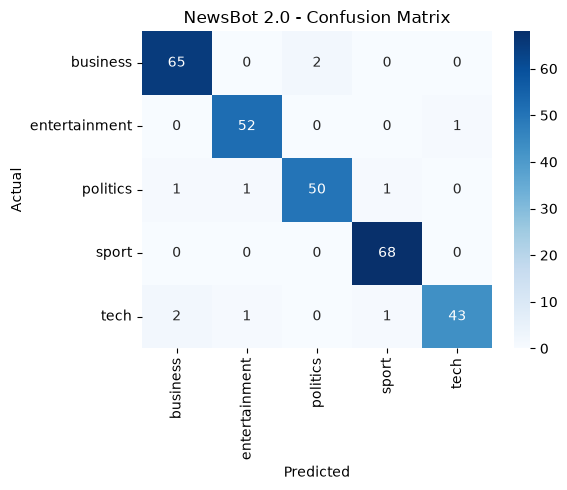

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(
    df['processed'], df['category'], test_size=0.2, random_state=42, stratify=df['category'])

news_clf = NewsClassifier()
comparison = pd.DataFrame(news_clf.compare_models(X_train, y_train, X_test, y_test)).T
print('Model comparison (duplicates removed):')
print(comparison.round(4))

news_clf.fit(X_train, y_train, tune=True)
final_acc, final_report = news_clf.evaluate(X_test, y_test)
print('\nBest C:', news_clf.best_params)
print(f'Tuned Logistic Regression accuracy: {final_acc:.4f}')
print(final_report)

# Same pipeline on the midterm data WITH duplicates, to compare fairly with the midterm number
Xa, Xb, ya, yb = train_test_split(df_full['content'].apply(preprocess_text), df_full['category'],
                                  test_size=0.2, random_state=42, stratify=df_full['category'])
acc_with_dups = NewsClassifier().fit(Xa, ya, tune=True).evaluate(Xb, yb)[0]
print(f'Same model on the 1490-article midterm data (with duplicates): {acc_with_dups:.4f}')

cm = confusion_matrix(y_test, news_clf.predict(X_test), labels=news_clf.model.classes_)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=news_clf.model.classes_, yticklabels=news_clf.model.classes_)
plt.title('NewsBot 2.0 - Confusion Matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.tight_layout(); plt.show()

Average sentiment by category:
category
business         0.2381
entertainment    0.5900
politics         0.0541
sport            0.5492
tech             0.5330
Name: compound, dtype: float64


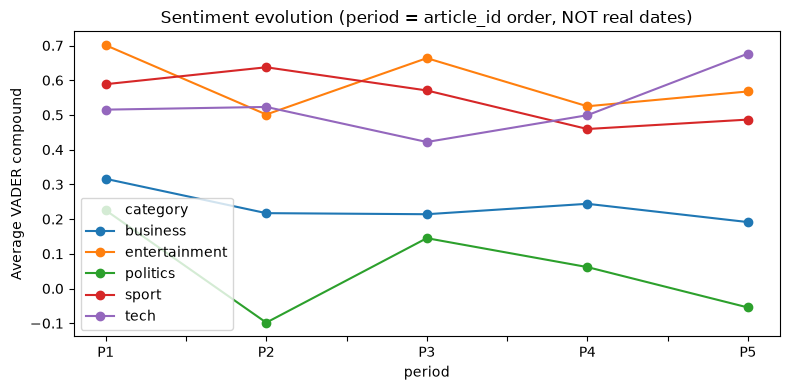

In [10]:
"""Module A: sentiment analysis (VADER, same as midterm) + sentiment evolution."""
import pandas as pd
import nltk
try:
    nltk.download("vader_lexicon", quiet=True)
except Exception:
    pass
from nltk.sentiment import SentimentIntensityAnalyzer


class SentimentAnalyzer:
    """VADER sentiment (same as midterm) with a simple label."""

    def __init__(self):
        self.sia = SentimentIntensityAnalyzer()

    def analyze(self, text):
        s = self.sia.polarity_scores(str(text))
        if s["compound"] >= 0.05:
            s["label"] = "positive"
        elif s["compound"] <= -0.05:
            s["label"] = "negative"
        else:
            s["label"] = "neutral"
        return s

    def analyze_df(self, df, text_col="content"):
        scores = df[text_col].map(self.analyze)
        out = df[["article_id", "category"]].copy()
        out["compound"] = scores.map(lambda s: s["compound"])
        out["label"] = scores.map(lambda s: s["label"])
        return out

    def sentiment_evolution(self, sent_df, time_col="period"):
        """Average sentiment per time period and category.
        NOTE: the BBC dataset has no dates, so we use article_id order split into
        periods as a stand-in for time. With a dated dataset, pass a real date column."""
        return sent_df.groupby([time_col, "category"])["compound"].mean().unstack()


sentiment_tool = SentimentAnalyzer()
sent_df = sentiment_tool.analyze_df(df)
sent_df['period'] = df['period'].values
print('Average sentiment by category:')
print(sent_df.groupby('category')['compound'].mean().round(4))
sentiment_tool.sentiment_evolution(sent_df).plot(marker='o', figsize=(8, 4))
plt.title('Sentiment evolution (period = article_id order, NOT real dates)')
plt.ylabel('Average VADER compound'); plt.tight_layout(); plt.show()

In [12]:
"""Module B: extractive summarization (TF-IDF scoring + TextRank)."""
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def summarize(text, n_sentences=3, method="textrank"):
    sents = split_sentences(text)
    if len(sents) <= n_sentences:
        return " ".join(sents)
    tfidf = TfidfVectorizer(stop_words="english").fit_transform(sents)
    if method == "tfidf":
        scores = np.asarray(tfidf.sum(axis=1)).ravel() / (np.asarray((tfidf > 0).sum(axis=1)).ravel() + 1)
    else:  # TextRank: PageRank over the sentence-similarity graph
        sim = cosine_similarity(tfidf)
        np.fill_diagonal(sim, 0)
        row = sim.sum(axis=1, keepdims=True)
        row[row == 0] = 1
        m = sim / row
        scores = np.ones(len(sents)) / len(sents)
        for _ in range(50):
            scores = 0.15 / len(sents) + 0.85 * m.T.dot(scores)
    top = sorted(np.argsort(scores)[::-1][:n_sentences])  # keep original order
    return " ".join(sents[i] for i in top)


def lead_baseline(text, n_sentences=3):
    return " ".join(split_sentences(text)[:n_sentences])


i = 5
print('ORIGINAL (first 400 chars):', df['content'][i][:400], '...\n')
print('TEXTRANK SUMMARY:', summarize(df['content'][i], 3), '\n')
print('LEAD-3 BASELINE:', lead_baseline(df['content'][i], 3))

ORIGINAL (first 400 chars): howard  truanted to play snooker  conservative leader michael howard has admitted he used to play truant to spend time with his school friends at a snooker hall.  mr howard said his time at jack s snooker hall in llanelli in the 1950s had not done him  any lasting damage . but he told the times educational supplement that truancy was  very bad  and said  firm action  was needed. mr howard also cal ...

TEXTRANK SUMMARY: howard  truanted to play snooker  conservative leader michael howard has admitted he used to play truant to spend time with his school friends at a snooker hall. mr howard said his time at jack s snooker hall in llanelli in the 1950s had not done him  any lasting damage . mr howard eventually left llanelli grammar school - and the snooker hall - to go to cambridge university. 

LEAD-3 BASELINE: howard  truanted to play snooker  conservative leader michael howard has admitted he used to play truant to spend time with his school friends at a sn

---
## 🅲 Module C: Multilingual Intelligence
Our models were trained on English, so our plan is: **detect the language → translate to English → use our English models**.
- Language detection: `langdetect`
- Translation: `deep-translator` (Google Translate, with MyMemory as a backup)
- If there is no internet or we hit a rate limit, the code does **not crash**: it just returns the original text and marks `translated=False`.

In [17]:
"""Module C: language detection with langdetect."""
try:
    from langdetect import detect_langs, DetectorFactory
    DetectorFactory.seed = 0
    HAVE_LANGDETECT = True
except ImportError:
    HAVE_LANGDETECT = False

LANG_NAMES = {"en": "English", "es": "Spanish", "fr": "French", "de": "German",
              "it": "Italian", "pt": "Portuguese", "ar": "Arabic", "zh-cn": "Chinese"}


def detect_language(text):
    """Return (language_code, probability)."""
    if not HAVE_LANGDETECT or not str(text).strip():
        return "unknown", 0.0
    try:
        best = detect_langs(str(text))[0]
        return best.lang, round(best.prob, 3)
    except Exception:
        return "unknown", 0.0


"""Module C: translation with deep-translator.
We try Google first, then MyMemory as a backup. If both fail (no internet or
rate limit), the original text is returned so the pipeline never crashes."""
import time

try:
    from deep_translator import GoogleTranslator, MyMemoryTranslator
    HAVE_TRANSLATOR = True
except ImportError:
    HAVE_TRANSLATOR = False

# MyMemory needs full locale codes
MYMEMORY_CODES = {"en": "en-GB", "es": "es-ES", "fr": "fr-FR", "de": "de-DE", "it": "it-IT",
                  "pt": "pt-PT", "ar": "ar-SA", "zh-CN": "zh-CN", "zh-cn": "zh-CN", "nl": "nl-NL"}


def translate(text, target="en", source="auto"):
    """Translate text. Returns (translated_text, ok_flag)."""
    if not HAVE_TRANSLATOR or not str(text).strip():
        return text, False
    text = str(text)[:4500]
    err = None
    try:
        return GoogleTranslator(source=source, target=target).translate(text), True
    except Exception as e:
        err = e
    if source != "auto":  # MyMemory cannot auto-detect, so it needs the source language
        try:
            time.sleep(0.5)
            out = MyMemoryTranslator(source=MYMEMORY_CODES.get(source, source),
                                     target=MYMEMORY_CODES.get(target, target)).translate(text[:480])
            return out, True
        except Exception as e:
            err = e
    print(f"[translation fallback] {type(err).__name__}: {str(err)[:80]}")
    return text, False


"""Module C: cross-language analysis.
Pipeline: detect language -> translate to English -> run our English models -> compare."""
import pandas as pd

class MultilingualAnalyzer:
    """Detect language -> translate to English -> run the English NewsBot models."""

    def __init__(self, classifier=None, sentiment=None):
        self.classifier = classifier
        self.sentiment = sentiment

    def analyze(self, text):
        lang, prob = detect_language(text)
        english, translated = (text, False) if lang == "en" else translate(text, "en", source=lang if lang != "unknown" else "auto")
        result = {"language": lang, "language_name": LANG_NAMES.get(lang, lang),
                  "confidence": prob, "translated": translated, "english_text": english}
        if self.classifier is not None:
            result["category"], result["category_confidence"] = self.classifier.predict_with_confidence(english)
        if self.sentiment is not None:
            s = self.sentiment.analyze(english)
            result["sentiment"], result["sentiment_score"] = s["label"], s["compound"]
        return result

    def compare(self, texts):
        """Cross-language comparison: analyze a list of texts (same story in different languages)."""
        rows = []
        for t in texts:
            r = self.analyze(t)
            rows.append({k: r.get(k) for k in ["language", "translated", "category", "category_confidence", "sentiment", "sentiment_score"]})
        return pd.DataFrame(rows)


    def coverage_comparison(self, stories):
        """stories = {"source/lang name": text}. Compare how each version is categorized and how
        positive/negative it sounds (a simple 'cultural context' / regional perspective check)."""
        df = self.compare(list(stories.values()))
        df.insert(0, "source", list(stories.keys()))
        return df

In [18]:
class RawTextClassifier:
    """Small wrapper so the multilingual module can send raw English text to our classifier."""
    def predict_with_confidence(self, text):
        return news_clf.predict_with_confidence(preprocess_text(text))

multi = MultilingualAnalyzer(RawTextClassifier(), sentiment_tool)

# Language detection test
for t in ['The government announced new taxes.', 'El gobierno anunció nuevos impuestos.',
          'Le gouvernement a annoncé de nouveaux impôts.', 'Die Regierung kündigte neue Steuern an.',
          'Il governo ha annunciato nuove tasse.']:
    print(detect_language(t), '|', t)

('en', 1.0) | The government announced new taxes.
('es', 1.0) | El gobierno anunció nuevos impuestos.
('fr', 1.0) | Le gouvernement a annoncé de nouveaux impôts.
('de', 1.0) | Die Regierung kündigte neue Steuern an.
('it', 1.0) | Il governo ha annunciato nuove tasse.


In [19]:
# Cross-language analysis: the same kind of story written by "different sources" in different languages
stories = {
    'UK source (English)':  'The national team won the championship final after a dramatic penalty shootout, and fans celebrated in the streets.',
    'Spain source (Spanish)': 'La selección nacional ganó la final del campeonato tras una dramática tanda de penaltis y los aficionados celebraron en las calles.',
    'France source (French)': "L'équipe nationale a remporté la finale du championnat après une séance de tirs au but dramatique, et les supporters ont fêté dans les rues.",
    'Germany source (German)': 'Die Wirtschaft schrumpfte im letzten Quartal, und die Bank warnte vor steigender Arbeitslosigkeit und höheren Preisen.',
}
coverage = multi.coverage_comparison(stories)
print(coverage.to_string())

                    source language  translated  category  category_confidence sentiment  sentiment_score
0      UK source (English)       en       False     sport             0.829053  positive           0.8074
1   Spain source (Spanish)       es        True     sport             0.829053  positive           0.8074
2   France source (French)       fr        True     sport             0.829053  positive           0.8074
3  Germany source (German)       de        True  business             0.967307  negative          -0.6124


In [20]:
# Round-trip test: translate 5 BBC article summaries to Spanish and back, then check if the category stays the same
rt_rows = []
for i in df.sample(5, random_state=7).index:
    summ = summarize(df['content'][i], 2)
    es, ok1 = translate(summ, target='es', source='en')
    time.sleep(1)
    r = multi.analyze(es)
    rt_rows.append({'id': i, 'true': df['category'][i], 'spanish_ok': ok1, 'detected': r['language'],
                    'back_to_en_ok': r['translated'], 'predicted': r['category']})
    time.sleep(1)
rt = pd.DataFrame(rt_rows)
print(rt)
if rt['spanish_ok'].all():
    print('Category kept after translation:', (rt['true'] == rt['predicted']).mean())
else:
    print('Translation service was not available for some rows (offline or rate limit) - fallback used.')

    id           true  spanish_ok detected  back_to_en_ok      predicted
0  810           tech        True       es           True           tech
1  489           tech        True       es           True           tech
2  799          sport        True       es           True          sport
3  680          sport        True       es           True          sport
4  898  entertainment        True       es           True  entertainment
Category kept after translation: 1.0


**Cultural context (simple version):** by comparing the tone and category of the same event from different
language sources, we can see if one region reports it more positively or negatively. With real articles from
different countries this would show regional perspectives. Our version is small because the BBC dataset is only English.